# Artificial Neural Network - Task 03 (Single-Layer Perceptron from Scratch (NumPy))

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

## 1. Load the dataset

In [3]:
df=pd.read_csv(r"C:\Users\STRIKER\Downloads\banknote_authentication.csv", header=None, names=['variance','skewness','curtosis','entropy','class'])
print("data set loaded successfully")
df.head()

data set loaded successfully


,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


In [4]:
df.tail()

,variance,skewness,curtosis,entropy,class
1367,0.40614,1.34920,-1.4501,-0.55949,1
1368,-1.38870,-4.87730,6.4774,0.34179,1
1369,-3.75030,-13.45860,17.5932,-2.77710,1
1370,-3.56370,-8.38270,12.3930,-1.28230,1
1371,-2.54190,-0.65804,2.6842,1.19520,1


In [5]:
df.shape

(1372, 5)

In [6]:
df.columns

Index(['variance', 'skewness', 'curtosis', 'entropy', 'class'], dtype='str')

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   variance  1372 non-null   float64
 1   skewness  1372 non-null   float64
 2   curtosis  1372 non-null   float64
 3   entropy   1372 non-null   float64
 4   class     1372 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB


In [8]:
df.describe()

,variance,skewness,curtosis,entropy,class
count,1372.000000,1372.000000,1372.000000,1372.000000,1372.000000
mean,0.433735,1.922353,1.397627,-1.191657,0.444606
std,2.842763,5.869047,4.310030,2.101013,0.497103
min,-7.042100,-13.773100,-5.286100,-8.548200,0.000000
25%,-1.773000,-1.708200,-1.574975,-2.413450,0.000000
50%,0.496180,2.319650,0.616630,-0.586650,0.000000
75%,2.821475,6.814625,3.179250,0.394810,1.000000
max,6.824800,12.951600,17.927400,2.449500,1.000000


## 2. Preprocessing

In [9]:
df.isnull().sum()

variance    0
skewness    0
curtosis    0
entropy     0
class       0
dtype: int64

In [10]:
print("duplicate rows:", df.duplicated().sum())

duplicate rows: 24


In [11]:
#The file has no id or empty columns, so only the duplicate rows are removed.
df=df.drop_duplicates()
df.shape

(1348, 5)

The target column `class` already has numbers (0 = genuine, 1 = forged), so no encoding is needed.

In [12]:
print(df['class'].value_counts())

class
0    738
1    610
Name: count, dtype: int64


In [13]:
y=df['class'].values
x=df.drop(columns=['class']).values
print("x shape:",x.shape)
print("y shape:",y.shape)

x shape: (1348, 4)
y shape: (1348,)


### Train-test split (70% train, 30% test)

In [14]:
x_train,x_test,y_train,y_test=train_test_split(x,y, test_size=0.3, random_state=42)

In [15]:
print("training shape:", x_train.shape)
print("testing shape:", x_test.shape)

training shape: (943, 4)
testing shape: (405, 4)


### Feature scaling (standardization)
The mean and standard deviation are taken from the training data only, and then used on both train and test data.

In [16]:
mean=x_train.mean(axis=0)
std=x_train.std(axis=0)
std[std==0]=1

x_train=(x_train-mean)/std
x_test=(x_test-mean)/std
print("scaling done")

scaling done


## 3. Single-Layer Perceptron 

In [17]:
class Perceptron:

    def __init__(self, learning_rate=0.01, epochs=50):
        self.lr=learning_rate
        self.epochs=epochs
        self.weights=None
        self.bias=0
        self.errors=[]

    def net_input(self, x):
        return np.dot(x, self.weights)+self.bias

    def predict(self, x):
        return np.where(self.net_input(x)>=0, 1, 0)

    def fit(self, x, y):
        n_samples, n_features = x.shape
        self.weights=np.zeros(n_features)
        self.bias=0
        self.errors=[]

        for epoch in range(self.epochs):
            wrong=0
            for xi, target in zip(x, y):
                pred=self.predict(xi)
                update=self.lr*(target-pred)
                self.weights=self.weights+update*xi
                self.bias=self.bias+update
                if update!=0:
                    wrong+=1
            self.errors.append(wrong)
            print("Epoch", epoch+1, "- misclassified:", wrong)

## 4. Train the model

In [18]:
model=Perceptron(learning_rate=0.01, epochs=50)
model.fit(x_train, y_train)
print("model train succesfully")

Epoch 1 - misclassified: 44
Epoch 2 - misclassified: 11
Epoch 3 - misclassified: 18
Epoch 4 - misclassified: 16
Epoch 5 - misclassified: 15
Epoch 6 - misclassified: 11
Epoch 7 - misclassified: 8
Epoch 8 - misclassified: 11
Epoch 9 - misclassified: 11
Epoch 10 - misclassified: 14
Epoch 11 - misclassified: 8
Epoch 12 - misclassified: 13
Epoch 13 - misclassified: 7
Epoch 14 - misclassified: 11
Epoch 15 - misclassified: 8
Epoch 16 - misclassified: 8
Epoch 17 - misclassified: 8
Epoch 18 - misclassified: 10
Epoch 19 - misclassified: 12
Epoch 20 - misclassified: 17
Epoch 21 - misclassified: 11
Epoch 22 - misclassified: 13
Epoch 23 - misclassified: 6
Epoch 24 - misclassified: 12
Epoch 25 - misclassified: 9
Epoch 26 - misclassified: 13
Epoch 27 - misclassified: 12
Epoch 28 - misclassified: 10
Epoch 29 - misclassified: 7
Epoch 30 - misclassified: 10
Epoch 31 - misclassified: 7
Epoch 32 - misclassified: 5
Epoch 33 - misclassified: 9
Epoch 34 - misclassified: 7
Epoch 35 - misclassified: 12
Epoch 3

## 5. Predictions

In [19]:
y_pred_train=model.predict(x_train)
y_pred=model.predict(x_test)

## 6. Evaluation (metrics written from scratch)

In [20]:
TP=np.sum((y_test==1)&(y_pred==1))
TN=np.sum((y_test==0)&(y_pred==0))
FP=np.sum((y_test==0)&(y_pred==1))
FN=np.sum((y_test==1)&(y_pred==0))

accuracy=(TP+TN)/(TP+TN+FP+FN)
precision=TP/(TP+FP)
recall=TP/(TP+FN)
f1=2*precision*recall/(precision+recall)

train_accuracy=np.mean(y_pred_train==y_train)

print("Confusion Matrix:")
print("TN:",TN," FP:",FP)
print("FN:",FN," TP:",TP)
print()
print("train accuracy:",round(train_accuracy,4))
print("test accuracy :",round(accuracy,4))
print("precision     :",round(precision,4))
print("recall        :",round(recall,4))
print("f1_score      :",round(f1,4))

Confusion Matrix:
TN: 219  FP: 2
FN: 2  TP: 182

train accuracy: 0.9926
test accuracy : 0.9901
precision     : 0.9891
recall        : 0.9891
f1_score      : 0.9891


In [21]:
results=pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred
})
results['Correct']=(results['Actual']==results['Predicted'])
results.head(10)

,Actual,Predicted,Correct
0,0,0,True
1,1,1,True
2,1,1,True
3,1,1,True
4,1,1,True
5,1,1,True
6,1,1,True
7,1,1,True
8,1,1,True
9,0,0,True


## 7. Visualizations

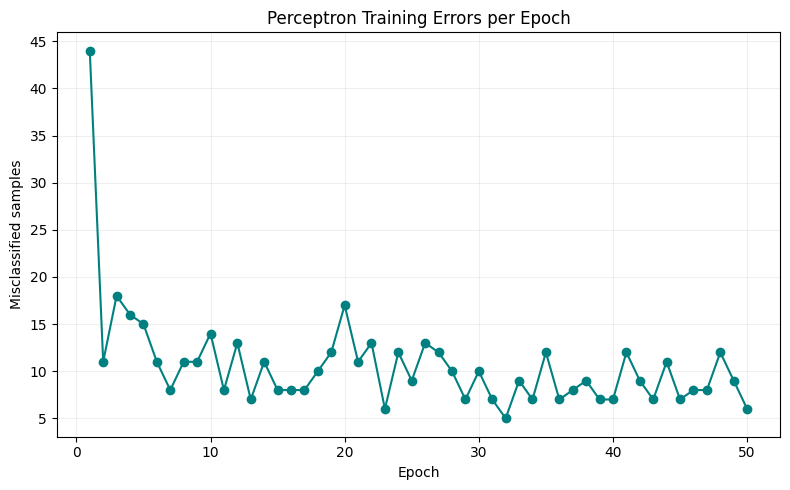

In [22]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(model.errors)+1), model.errors, marker='o', color='teal')
plt.xlabel("Epoch")
plt.ylabel("Misclassified samples")
plt.title("Perceptron Training Errors per Epoch")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

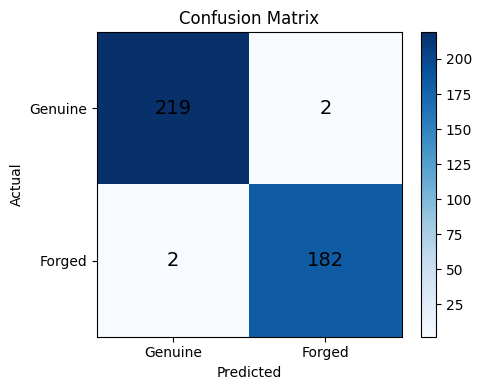

In [23]:
cm=np.array([[TN, FP],
             [FN, TP]])

plt.figure(figsize=(5, 4))
plt.imshow(cm, cmap='Blues')
plt.colorbar()
plt.xticks([0, 1], ['Genuine', 'Forged'])
plt.yticks([0, 1], ['Genuine', 'Forged'])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center', fontsize=14)

plt.tight_layout()
plt.show()

## 8. Conclusion
- A Single-Layer Perceptron was built from scratch using only NumPy (no prebuilt ML model).
- The dataset was cleaned, the features were standardized, and the data was split 70/30.
- The model learned by the perceptron rule and the errors per epoch are shown in the plot above.
- The final performance on the test data is shown above using accuracy, precision, recall, F1-score and the confusion matrix.